# 01 — Explorer les redondances et construire des variables candidates

**Question :** quelles colonnes apportent une information proche, et quelles combinaisons auraient un sens RH ? Base : `data/variantes/01_baseline.xlsx`, 31 colonnes, valeurs inchangées. L’audit détaillé reste dans le notebook 00.

Une variable dérivée réorganise l’information existante ; elle n’ajoute pas une nouvelle mesure. Elle peut rendre un rapport plus lisible ou exprimer une interaction utile à la logistique. **Aucune variable n’est ajoutée aux modèles 04/05 dans ce notebook.**

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "features.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "features.py").exists():
    raise RuntimeError("Lancer depuis la racine ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from hashlib import sha256
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from src.data import export_table
from src.modeling import load_model_data, make_split, DATA_PATH, SCORES
from src.features import numeric_redundancies, build_candidates, fit_income_reference, relative_income
from src.plots import save_figure
fingerprint = sha256(DATA_PATH.read_bytes()).hexdigest()
X, y, source_rows, groups, quantitative = load_model_data()
original = X.copy(deep=True)
print(DATA_PATH.relative_to(ROOT), "—", len(X), "salariés,", X.shape[1], "variables explicatives")

data/variantes/01_baseline.xlsx — 1518 salariés, 30 variables explicatives


## 1. Vérifier le socle et isoler l’entraînement
La baseline a déjà retiré les trois constantes et l’identifiant. `Attrition` et `depart` sont absents de X. Les quatre anciens contrôles d’ancienneté restent visibles : ces incohérences ne sont pas corrigées.

Le split est le même 80/20 stratifié que dans les modèles, `random_state=42`. **Toutes les corrélations, distributions de variables candidates et références ci-dessous utilisent uniquement l’entraînement.** La cible n’est pas utilisée pour classer les variables candidates ; on évite d’en choisir à partir des résultats du test.

In [2]:
X_train, X_test, y_train, y_test, folds, split_rows = make_split(X, y, source_rows)
print("Entraînement :", len(X_train), "; test réservé :", len(X_test))
quality = pd.DataFrame({"type": X.dtypes.astype(str), "manquantes": X.isna().sum(), "modalites": X.nunique()})
display(export_table(quality, "01_qualite", index=True))
print("Constantes :", X.columns[X.nunique().le(1)].tolist())
print("Doublons des variables explicatives :", X.duplicated().sum())
controls = pd.DataFrame({a + " > " + b: X[a] > X[b] for a,b in [
    ("YearsAtCompany", "TotalWorkingYears"), ("YearsInCurrentRole", "YearsAtCompany"),
    ("YearsSinceLastPromotion", "YearsAtCompany"), ("YearsWithCurrManager", "YearsAtCompany")]})
display(export_table(controls.sum().rename("alertes").to_frame(), "01_controles", index=True))

Entraînement : 1214 ; test réservé : 304


,type,manquantes,modalites
Age,int64,0,44
BusinessTravel,object,0,3
DailyRate,int64,0,901
Department,object,0,3
DistanceFromHome,int64,0,30
Education,int64,0,7
EducationField,object,0,6
EnvironmentSatisfaction,int64,0,6
Gender,object,0,2
HourlyRate,int64,0,72


Constantes : []
Doublons des variables explicatives : 0


,alertes
YearsAtCompany > TotalWorkingYears,6
YearsInCurrentRole > YearsAtCompany,7
YearsSinceLastPromotion > YearsAtCompany,4
YearsWithCurrManager > YearsAtCompany,6


## 2. Chercher les redondances numériques
**Pearson** mesure une association linéaire ; **Spearman** compare les rangs et repère des relations monotones. Une forte corrélation suggère un recouvrement, pas une identité ni une causalité. Une faible corrélation n’exclut pas une relation non linéaire.

Le repère |corrélation| ≥ 0,75 sert à attirer l’attention, pas à supprimer automatiquement une colonne. La matrice porte sur les quantitatives ; les scores sont examinés séparément pour ne pas supposer que leurs codes ont des intervalles comparables.

,variable_1,variable_2,pearson,spearman,correlation_max_absolue
85,YearsAtCompany,YearsInCurrentRole,0.742055,0.844410,0.844410
87,YearsAtCompany,YearsWithCurrManager,0.768029,0.838662,0.838662
49,MonthlyIncome,TotalWorkingYears,0.764336,0.700773,0.764336
89,YearsInCurrentRole,YearsWithCurrManager,0.707722,0.718197,0.718197
7,Age,TotalWorkingYears,0.666975,0.647720,0.666975
77,TotalWorkingYears,YearsAtCompany,0.636259,0.595060,0.636259
86,YearsAtCompany,YearsSinceLastPromotion,0.605256,0.503525,0.605256
88,YearsInCurrentRole,YearsSinceLastPromotion,0.538177,0.506073,0.538177
51,MonthlyIncome,YearsAtCompany,0.509037,0.469939,0.509037
90,YearsSinceLastPromotion,YearsWithCurrManager,0.497433,0.457334,0.497433


,variable_1,variable_2,pearson,spearman,correlation_max_absolue
85,YearsAtCompany,YearsInCurrentRole,0.742055,0.844410,0.844410
87,YearsAtCompany,YearsWithCurrManager,0.768029,0.838662,0.838662
49,MonthlyIncome,TotalWorkingYears,0.764336,0.700773,0.764336


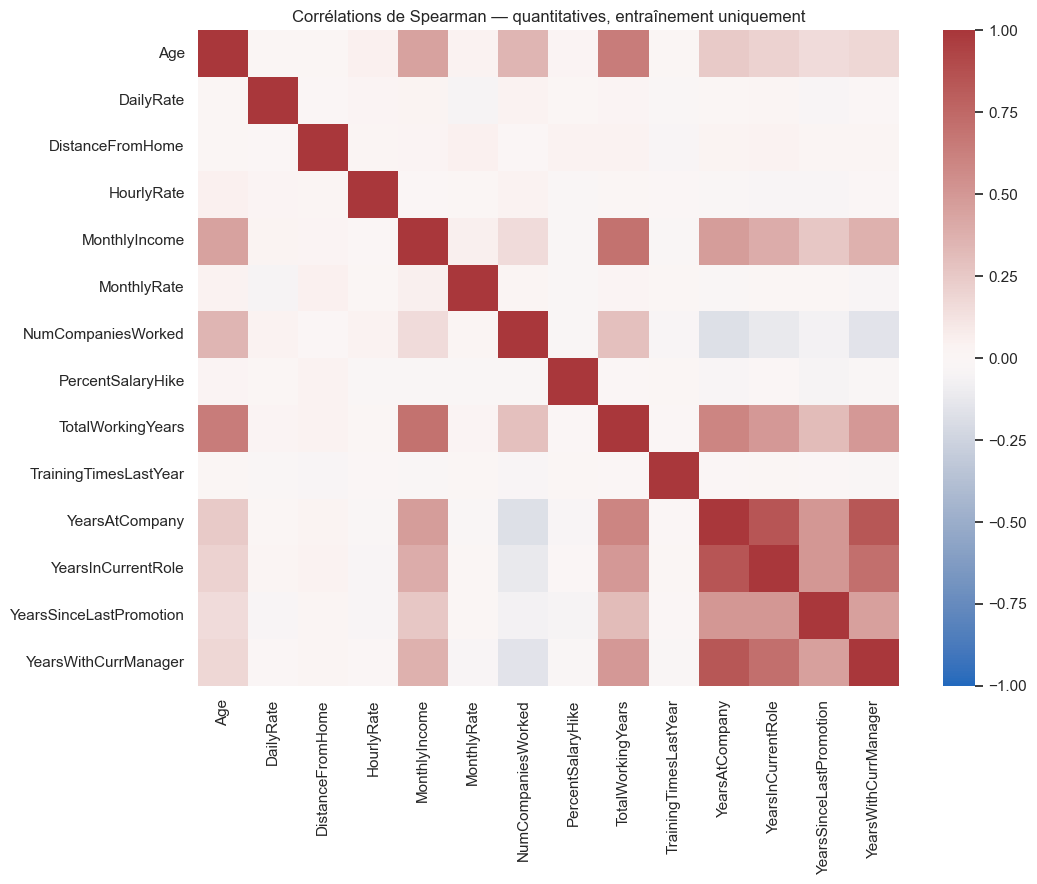

In [3]:
pairs, correlation = numeric_redundancies(X_train, quantitative)
export_table(pairs, "01_correlations_quantitatives")
display(pairs.head(20))
display(pairs.loc[pairs.correlation_max_absolue.ge(.75)])
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlation, vmin=-1, vmax=1, center=0, cmap="vlag", ax=ax)
ax.set_title("Corrélations de Spearman — quantitatives, entraînement uniquement")
save_figure(fig, "01_correlations_quantitatives")

## 3. Examiner le salaire, le niveau et l’expérience
Un niveau élevé peut coïncider avec un revenu et une expérience plus élevés. Les variables peuvent donc se partager le même signal dans une régression, ce qui complique la lecture de leurs coefficients. Cela ne justifie pas de supprimer le revenu lorsque la question RH concerne la rémunération.

Les codes de niveau sont utilisés ici pour un diagnostic de rangs, pas pour valider le dictionnaire. Une relation entre revenu et MonthlyRate/DailyRate/HourlyRate ne suffit pas à prouver qu’ils mesurent le même concept.

,variable_1,variable_2,pearson,spearman,correlation_max_absolue
0,MonthlyIncome,JobLevel,0.931609,0.902860,0.931609
2,MonthlyIncome,TotalWorkingYears,0.764336,0.700773,0.764336
8,JobLevel,TotalWorkingYears,0.759861,0.710562,0.759861
13,Age,TotalWorkingYears,0.666975,0.647720,0.666975
18,TotalWorkingYears,YearsAtCompany,0.636259,0.595060,0.636259
9,JobLevel,YearsAtCompany,0.518539,0.467298,0.518539
3,MonthlyIncome,YearsAtCompany,0.509037,0.469939,0.509037
7,JobLevel,Age,0.489353,0.468498,0.489353
1,MonthlyIncome,Age,0.479721,0.449605,0.479721
14,Age,YearsAtCompany,0.308896,0.248331,0.308896


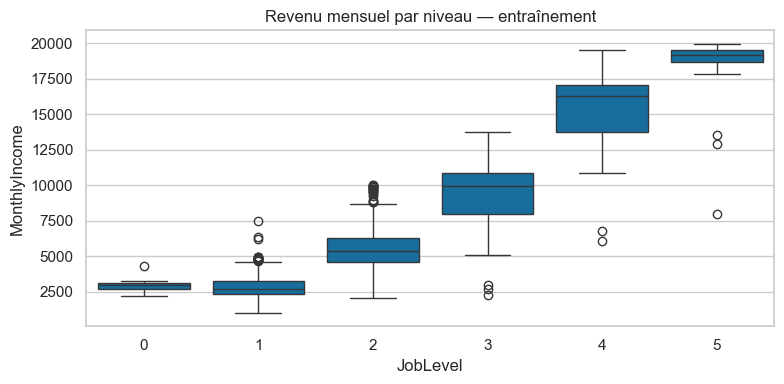

In [4]:
salary_columns = ["MonthlyIncome", "JobLevel", "Age", "TotalWorkingYears", "YearsAtCompany",
                  "MonthlyRate", "DailyRate", "HourlyRate"]
salary_pairs, _ = numeric_redundancies(X_train, salary_columns)
display(export_table(salary_pairs, "01_redondances_remuneration"))
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=X_train, x="JobLevel", y="MonthlyIncome", ax=ax)
ax.set_title("Revenu mensuel par niveau — entraînement")
save_figure(fig, "01_revenu_niveau")

## 4. Métier et département : une information répétée ?
Le tableau croisé indique si un métier est presque toujours rattaché au même département. On affiche pour chaque métier son département majoritaire, l’effectif, le nombre de départements et la part majoritaire.

Une correspondance parfaite dans l’échantillon ne garantit pas une règle universelle. Deux colonnes peuvent être utiles à la description organisationnelle mais largement redondantes pour un modèle.

In [5]:
cross = pd.crosstab(X_train.JobRole, X_train.Department)
export_table(cross, "01_metier_departement", index=True)
mapping = pd.DataFrame({"effectif": cross.sum(axis=1), "departements_observes": cross.gt(0).sum(axis=1),
    "departement_majoritaire": cross.idxmax(axis=1), "part_majoritaire": cross.max(axis=1)/cross.sum(axis=1)})
display(export_table(mapping, "01_recouvrement_metier_departement", index=True))
print("Part des salariés correspondant au département majoritaire de leur métier :",
      f"{cross.max(axis=1).sum()/cross.to_numpy().sum():.1%}")
score_corr = X_train[SCORES].corr(method="spearman")
display(export_table(score_corr, "01_correlations_scores", index=True))

,effectif,departements_observes,departement_majoritaire,part_majoritaire
JobRole,,,,
Healthcare Representative,111,1,Research & Development,1.000000
Human Resources,41,1,Human Resources,1.000000
Laboratory Technician,209,1,Research & Development,1.000000
Manager,82,3,Research & Development,0.560976
Manufacturing Director,119,1,Research & Development,1.000000
Research Director,66,1,Research & Development,1.000000
Research Scientist,239,1,Research & Development,1.000000
Sales Executive,278,1,Sales,1.000000
Sales Representative,69,1,Sales,1.000000


Part des salariés correspondant au département majoritaire de leur métier : 97.0%


,Education,EnvironmentSatisfaction,JobInvolvement,JobLevel,JobSatisfaction,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,WorkLifeBalance
Education,1.000000,-0.035971,0.008173,0.110812,-0.006518,0.001894,0.015550,0.019730,0.040630
EnvironmentSatisfaction,-0.035971,1.000000,-0.015008,0.007004,0.010014,-0.025526,0.044222,0.011912,0.050209
JobInvolvement,0.008173,-0.015008,1.000000,-0.027541,-0.022368,-0.047210,0.019385,0.025651,-0.013964
JobLevel,0.110812,0.007004,-0.027541,1.000000,0.003065,0.007800,-0.000005,0.027294,0.042049
JobSatisfaction,-0.006518,0.010014,-0.022368,0.003065,1.000000,0.008678,0.005171,0.022860,-0.027610
PerformanceRating,0.001894,-0.025526,-0.047210,0.007800,0.008678,1.000000,-0.029903,0.025068,-0.003475
RelationshipSatisfaction,0.015550,0.044222,0.019385,-0.000005,0.005171,-0.029903,1.000000,-0.073994,0.060439
StockOptionLevel,0.019730,0.011912,0.025651,0.027294,0.022860,0.025068,-0.073994,1.000000,0.009501
WorkLifeBalance,0.040630,0.050209,-0.013964,0.042049,-0.027610,-0.003475,0.060439,0.009501,1.000000


## 5. Définir des combinaisons interprétables

| Colonne candidate | Formule | Intérêt / réserve |
|---|---|---|
| PriorExperienceYears | TotalWorkingYears − YearsAtCompany | Expérience hors de l’entreprise, sous réserve des conventions d’ancienneté. |
| CompanyTenureShare | YearsAtCompany / TotalWorkingYears | Part de la carrière dans l’entreprise ; indéfinie si expérience totale nulle. |
| YearsBeforeCurrentRole | YearsAtCompany − YearsInCurrentRole | Ancienneté acquise avant le rôle actuel ; pas un nombre de promotions. |
| RoleTenureShare | YearsInCurrentRole / YearsAtCompany | Part de l’ancienneté dans le rôle actuel ; n’est pas une preuve de stagnation. |
| YearsBeforeCurrentManager | YearsAtCompany − YearsWithCurrManager | Ancienneté avant le manager actuel ; pas une mesure de qualité du management. |
| OverTimeFrequentTravel | OverTime=Yes ET BusinessTravel=Travel_Frequently | Cumul de deux contraintes déclarées, sans volume mesuré. |
| DistanceIfOverTime | DistanceFromHome × indicatrice OverTime | Interaction : la relation avec la distance peut différer selon les heures supplémentaires. |

Une incohérence d’ancienneté ou une division par zéro rend **uniquement la nouvelle variable concernée non calculable (NaN)**. Aucune cellule source n’est modifiée ; aucune ligne n’est supprimée. Un zéro de ratio n’est pas inventé pour remplacer une division impossible.

,count,mean,std,min,25%,50%,75%,max,non_calculables
PriorExperienceYears,1208.0,4.245861,6.096163,0.0,0.000000,2.000000,5.000000,31.0,6
CompanyTenureShare,1197.0,0.681565,0.321806,0.0,0.428571,0.800000,1.000000,1.0,17
YearsBeforeCurrentRole,1203.0,2.849543,4.255736,0.0,1.000000,1.000000,3.000000,30.0,11
RoleTenureShare,1162.0,0.600502,0.316593,0.0,0.400000,0.666667,0.846154,1.0,52
YearsBeforeCurrentManager,1204.0,2.909468,4.118681,0.0,1.000000,1.000000,3.000000,34.0,10
OverTimeFrequentTravel,1214.0,0.058484,0.234754,0.0,0.000000,0.000000,0.000000,1.0,0
DistanceIfOverTime,1214.0,2.716639,6.043435,0.0,0.000000,0.000000,2.000000,29.0,0


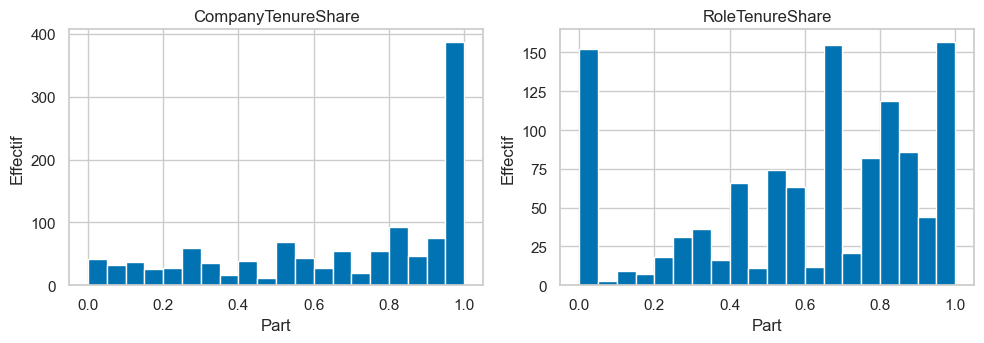

BusinessTravel,Non-Travel,Travel_Frequently,Travel_Rarely
OverTime,,,
No,103,156,604
Yes,31,71,249


In [6]:
candidates = build_candidates(X_train)
summary = candidates.describe().T
summary["non_calculables"] = candidates.isna().sum()
display(export_table(summary, "01_variables_candidates_resume", index=True))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col in zip(axes, ["CompanyTenureShare", "RoleTenureShare"]):
    ax.hist(candidates[col].dropna(), bins=20, edgecolor="white")
    ax.set(title=col, xlabel="Part", ylabel="Effectif")
save_figure(fig, "01_parts_anciennete")
exposures = pd.crosstab(X_train.OverTime, X_train.BusinessTravel)
display(export_table(exposures, "01_cumul_contraintes", index=True))

## 6. Revenu relatif au métier et au niveau
**IncomeToRoleLevelMedian = revenu / revenu médian du même métier et niveau dans l’entraînement.** Un ratio de 1 signifie le niveau de la médiane de référence ; 0,8 correspond à un revenu inférieur de 20 % à cette médiane. Ce n’est pas une preuve de sous-rémunération injustifiée : expérience, responsabilités et temps de travail peuvent différer.

On exige au moins cinq salariés par strate pour éviter les références les plus fragiles. C’est un seuil de prudence modifiable, pas une garantie. Pour une strate absente ou trop petite, le ratio reste NaN.

**Attention à la validation :** la référence ci-dessous sert à l’exploration sur l’entraînement. Si cette variable entre un jour dans un modèle, il faudra réapprendre les médianes dans chaque pli via un transformer du pipeline. Ne pas calculer ce ratio sur tout l’entraînement avant une validation croisée.

In [7]:
income_reference = fit_income_reference(X_train)
display(export_table(income_reference, "01_reference_revenu_metier_niveau"))
candidates["IncomeToRoleLevelMedian"] = relative_income(X_train, income_reference)
display(export_table(candidates[["IncomeToRoleLevelMedian"]].describe().T.assign(
    non_calculables=candidates.IncomeToRoleLevelMedian.isna().sum()), "01_revenu_relatif_resume", index=True))
print("Strates de moins de cinq salariés :", income_reference.reference_count.lt(5).sum())

,JobRole,JobLevel,median_income,reference_count
0,Healthcare Representative,2,5738.0,64
1,Healthcare Representative,3,9613.0,39
2,Healthcare Representative,4,12374.0,8
3,Human Resources,1,2706.0,27
4,Human Resources,2,5473.5,10
5,Human Resources,3,10337.5,4
6,Laboratory Technician,0,3102.0,2
7,Laboratory Technician,1,2661.0,155
8,Laboratory Technician,2,4627.0,49
9,Laboratory Technician,3,5210.0,3


,count,mean,std,min,25%,50%,75%,max,non_calculables
IncomeToRoleLevelMedian,1192.0,1.029534,0.244097,0.374954,0.879541,1.0,1.136827,2.075743,22


Strates de moins de cinq salariés : 11


## 7. Les nouvelles colonnes sont-elles elles-mêmes redondantes ?
Pour chaque candidate, on recherche la quantitative source la plus corrélée en rangs, et on conserve l’effectif de paires valides. Cela aide à repérer une transformation qui reproduirait presque une variable existante, mais ne mesure pas son gain prédictif.

Les différences sont des combinaisons linéaires exactes des colonnes de départ. Ajouter à la fois une différence et ses deux composantes n’apporte pas d’information nouvelle et peut compliquer les coefficients. Les interactions demandent généralement de conserver leurs effets principaux.

In [8]:
rows = []
for candidate in candidates:
    for source in quantitative:
        pair = pd.concat([candidates[candidate], X_train[source]], axis=1).dropna()
        value = pair.corr(method="spearman").iloc[0, 1]
        rows.append({"candidate": candidate, "source": source, "spearman": value, "effectif_valide": len(pair)})
links = pd.DataFrame(rows)
links["correlation_absolue"] = links.spearman.abs()
export_table(links, "01_correlations_candidates_sources")
best = links.sort_values("correlation_absolue", ascending=False).drop_duplicates("candidate")
display(export_table(best, "01_recouvrement_candidates"))

,candidate,source,spearman,effectif_valide,correlation_absolue
6,PriorExperienceYears,NumCompaniesWorked,0.685212,1208,0.685212
38,YearsBeforeCurrentRole,YearsAtCompany,0.662453,1203,0.662453
66,YearsBeforeCurrentManager,YearsAtCompany,0.660552,1204,0.660552
20,CompanyTenureShare,NumCompaniesWorked,-0.632665,1197,0.632665
53,RoleTenureShare,YearsInCurrentRole,0.508120,1162,0.508120
102,IncomeToRoleLevelMedian,MonthlyIncome,0.324363,1192,0.324363
86,DistanceIfOverTime,DistanceFromHome,0.136110,1214,0.136110
77,OverTimeFrequentTravel,PercentSalaryHike,-0.039199,1214,0.039199


## 8. Décider quoi essayer, sans modifier les modèles existants
- **À examiner comme alternatives :** expérience hors entreprise et parts d’ancienneté, en remplaçant éventuellement certaines composantes plutôt qu’en empilant les colonnes.
- **À tester avec leurs effets principaux :** cumul heures supplémentaires/déplacements et interaction distance/heures supplémentaires. Leur utilité est surtout à évaluer pour la logistique ; une forêt peut déjà apprendre des interactions.
- **À tester avec un transformer appris par pli :** revenu relatif au métier/niveau. Comparer un modèle avec les variables brutes à un modèle enrichi sur les mêmes plis d’entraînement.
- **À examiner pour simplification :** couples fortement corrélés et recouvrement métier/département ; aucune suppression automatique, car la question RH compte autant que la corrélation.
- **À ne pas construire sans définition :** salaire horaire à partir de MonthlyIncome et d’heures réellement travaillées absentes ; moyenne arbitraire de satisfaction ; « taux de promotion » à partir de YearsSinceLastPromotion.

Le test actuel a déjà été consulté pour les modèles 04/05 : il ne pourra pas devenir une preuve entièrement indépendante après de multiples changements de modèle. Choisir les variantes sur l’entraînement, puis chercher une nouvelle cohorte pour une validation finale.

Les CSV exportés sont agrégés ; aucune nouvelle version Excel ni prédiction individuelle n’est créée. L’absentéisme reste non mesurable ; ni causalité ni représentativité pour l’Afrique ne peuvent être établies ici.

In [9]:
pd.testing.assert_frame_equal(X, original)
assert sha256(DATA_PATH.read_bytes()).hexdigest() == fingerprint
assert candidates.index.equals(X_train.index)
assert not np.isinf(candidates.to_numpy(dtype=float)).any()
print("Baseline intacte ; toutes les lignes conservées ; modèles 04/05 inchangés.")

Baseline intacte ; toutes les lignes conservées ; modèles 04/05 inchangés.
